# Laugh vs. Choke — 3-Architecture Robust Comparison (6 Runs Each)

This notebook compares the three uploaded architectures under **one shared experimental protocol**:

1. **Multi-Fusion CNN** — Tonal / Transient / Energy branches.
2. **RNN (BiLSTM)** — frame embedding followed by a bidirectional LSTM.
3. **CRNN (CNN-BiGRU)** — convolutional feature extraction followed by a bidirectional GRU.

## Important comparison choice

The three original notebooks did not use a perfectly identical pipeline. For a defensible architecture comparison, this notebook preserves the **architectures** but standardizes everything else:

- the same prepared `processed/train`, `processed/val`, and `processed/test` folders;
- train-set channel normalization from `norm_stats.json`;
- the same class-weighted cross-entropy;
- the same optimizer, learning rate, weight decay, scheduler, gradient clipping, early stopping, and batch size;
- the same six paired random seeds;
- the same fixed test set and metric calculation.

The test set is used **only after** the best checkpoint has been selected by validation loss.

### Outputs

The notebook produces:

- all 18 individual run results;
- mean ± sample standard deviation across six runs;
- accuracy;
- choking precision, recall, and F1;
- laughter precision, recall, and F1;
- macro precision, recall, and F1;
- mean ± SD confusion matrices;
- pairwise prediction-agreement checks;
- CSV, JSON, checkpoint, and figure files saved to Google Drive.

Because the training protocol is now unified, these new values should be treated as the primary architecture-comparison results. They do not have to reproduce older one-off runs exactly.

In [ ]:
# ============================================================
# 0. Imports + Google Drive
# ============================================================
import os
os.environ["CUBLAS_WORKSPACE_CONFIG"] = ":4096:8"

import gc
import json
import random
import re
from itertools import combinations
from pathlib import Path
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    precision_recall_fscore_support,
)

from google.colab import drive
drive.mount("/content/drive")

print("PyTorch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

Mounted at /content/drive
PyTorch: 2.11.0+cu128
CUDA available: True


In [ ]:
# ============================================================
# 1. Experiment configuration
# ============================================================
PROJECT_DIR = Path("/content/drive/MyDrive/פרוייקט גמר- זיהוי רעשים")
PROCESSED_DIR = PROJECT_DIR / "processed"

META_PATH = PROCESSED_DIR / "meta.json"
NORM_PATH = PROCESSED_DIR / "norm_stats.json"
MANIFEST_PATH = PROCESSED_DIR / "manifest.json"

OUT_DIR = PROJECT_DIR / "architecture_comparison_6runs"
CHECKPOINT_DIR = OUT_DIR / "checkpoints"
FIGURE_DIR = OUT_DIR / "figures"

OUT_DIR.mkdir(parents=True, exist_ok=True)
CHECKPOINT_DIR.mkdir(parents=True, exist_ok=True)
FIGURE_DIR.mkdir(parents=True, exist_ok=True)

# Six paired runs: every architecture uses these same seeds.
RUN_SEEDS = [42, 43, 44, 45, 46, 47]
NUM_RUNS = len(RUN_SEEDS)

# Shared training protocol.
BATCH_SIZE = 16
LEARNING_RATE = 5e-4
WEIGHT_DECAY = 1e-3
NUM_EPOCHS = 25
EARLY_STOPPING_PATIENCE = 8
SCHEDULER_PATIENCE = 4
SCHEDULER_FACTOR = 0.5
GRAD_CLIP = 5.0

USE_CLASS_WEIGHTS = True
VERBOSE_EPOCHS = False
DETERMINISTIC = True

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Device:", device)
print("Processed data:", PROCESSED_DIR)
print("Output directory:", OUT_DIR)
print("Runs per architecture:", NUM_RUNS)
print("Seeds:", RUN_SEEDS)

Device: cuda
Processed data: /content/drive/MyDrive/פרוייקט גמר- זיהוי רעשים/processed
Output directory: /content/drive/MyDrive/פרוייקט גמר- זיהוי רעשים/architecture_comparison_6runs
Runs per architecture: 6
Seeds: [42, 43, 44, 45, 46, 47]


In [ ]:
# ============================================================
# 2. Reproducibility
# ============================================================
def set_seed(seed: int):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)

    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

    if DETERMINISTIC:
        torch.backends.cudnn.benchmark = False
        torch.backends.cudnn.deterministic = True
        torch.use_deterministic_algorithms(True, warn_only=True)

set_seed(RUN_SEEDS[0])

In [ ]:
# ============================================================
# 3. Load metadata and train normalization statistics
# ============================================================
for required_path in [META_PATH, NORM_PATH, MANIFEST_PATH]:
    if not required_path.exists():
        raise FileNotFoundError(f"Required file not found: {required_path}")

with open(META_PATH, "r", encoding="utf-8") as f:
    meta = json.load(f)

with open(NORM_PATH, "r", encoding="utf-8") as f:
    norm_stats = json.load(f)

with open(MANIFEST_PATH, "r", encoding="utf-8") as f:
    manifest = json.load(f)

CHANNEL_NAMES = list(meta["channels"])
N_CHANNELS = int(meta["n_channels"])
HEIGHT = int(meta["tensor_shape"][1])
WIDTH = int(meta["tensor_shape"][2])
INPUT_SHAPE = (N_CHANNELS, HEIGHT, WIDTH)

CLASS_NAMES = ["choking", "laughter"]
NUM_CLASSES = len(CLASS_NAMES)
CLASS_TO_IDX = {name: i for i, name in enumerate(CLASS_NAMES)}

assert N_CHANNELS == 20, f"Expected 20 channels, found {N_CHANNELS}"
assert len(CHANNEL_NAMES) == N_CHANNELS
assert len(norm_stats["mean"]) == N_CHANNELS
assert len(norm_stats["std"]) == N_CHANNELS

print("Channels:", CHANNEL_NAMES)
print("Input shape:", INPUT_SHAPE)
print("Classes:", CLASS_TO_IDX)

print("\nManifest original-file counts:")
for split in ["train", "val", "test"]:
    print(split, manifest["counts"][split])

Channels: ['log_mel', 'harmonic_mel', 'percussive_mel', 'delta', 'delta_delta', 'zcr', 'rms', 'spectral_centroid', 'spectral_rolloff', 'spectral_bandwidth', 'spectral_contrast', 'chroma', 'mfcc', 'tonnetz', 'spectral_flatness', 'f0', 'voiced_prob', 'spectral_flux', 'wide_band_mel', 'rms_periodicity']
Input shape: (20, 128, 128)
Classes: {'choking': 0, 'laughter': 1}

Manifest original-file counts:
train {'choking': 88, 'laughter': 72}
val {'choking': 17, 'laughter': 23}
test {'choking': 34, 'laughter': 25}


In [ ]:
# ============================================================
# 4. Collect the fixed train / val / test splits
# ============================================================
def collect_split_samples(split_name: str):
    split_dir = PROCESSED_DIR / split_name

    if not split_dir.exists():
        raise FileNotFoundError(f"Split directory not found: {split_dir}")

    samples = []

    for class_name in CLASS_NAMES:
        class_dir = split_dir / class_name

        if not class_dir.exists():
            raise FileNotFoundError(f"Class directory not found: {class_dir}")

        label = CLASS_TO_IDX[class_name]

        for file_path in sorted(class_dir.rglob("*.npy")):
            samples.append((file_path, label))

    if not samples:
        raise ValueError(f"No .npy files found in {split_dir}")

    return samples


train_samples = collect_split_samples("train")
val_samples = collect_split_samples("val")
test_samples = collect_split_samples("test")


def split_counts(samples):
    counts = Counter(label for _, label in samples)
    return {
        CLASS_NAMES[i]: int(counts.get(i, 0))
        for i in range(NUM_CLASSES)
    }


print("Tensor counts after preprocessing:")
print("Train:", len(train_samples), split_counts(train_samples))
print("Val:  ", len(val_samples), split_counts(val_samples))
print("Test: ", len(test_samples), split_counts(test_samples))

Tensor counts after preprocessing:
Train: 640 {'choking': 352, 'laughter': 288}
Val:   80 {'choking': 34, 'laughter': 46}
Test:  59 {'choking': 34, 'laughter': 25}


## Leakage sanity check

The split folders are already fixed by the prepare/preprocessing pipeline, so every architecture receives the same split.

The check below also strips the augmentation suffixes used in the project and generated window suffixes such as `_w0` or `__w0` before comparing recording identities between splits.

In [ ]:
# ============================================================
# 5. Filename-based original-recording leakage check
# ============================================================
AUGMENTATION_SUFFIXES = [
    "_noise",
    "_ts0.85",
    "_ts1.15",
    "_ps-2",
    "_ps+2",
]


def base_recording_id(sample):
    path, label = sample
    stem = path.stem
    class_name = CLASS_NAMES[label]

    changed = True

    while changed:
        changed = False

        for suffix in AUGMENTATION_SUFFIXES:
            if stem.endswith(suffix):
                stem = stem[:-len(suffix)]
                changed = True
                break

        # Prepared window suffixes: _w0, __w0, _w1, ...
        new_stem = re.sub(r"_+w\d+$", "", stem)

        if new_stem != stem:
            stem = new_stem
            changed = True

    return f"{class_name}/{stem}"


train_ids = {base_recording_id(s) for s in train_samples}
val_ids = {base_recording_id(s) for s in val_samples}
test_ids = {base_recording_id(s) for s in test_samples}

overlaps = {
    "train/val": train_ids & val_ids,
    "train/test": train_ids & test_ids,
    "val/test": val_ids & test_ids,
}

for name, overlap in overlaps.items():
    print(f"{name} overlap:", len(overlap))

    if overlap:
        print("Examples:", sorted(overlap)[:10])

assert not overlaps["train/val"], "Potential recording leakage between train and val."
assert not overlaps["train/test"], "Potential recording leakage between train and test."
assert not overlaps["val/test"], "Potential recording leakage between val and test."

print("\nNo original-recording leakage detected by filename identity.")

train/val overlap: 0
train/test overlap: 0
val/test overlap: 0

No original-recording leakage detected by filename identity.


In [ ]:
# ============================================================
# 6. Shared normalized dataset and paired DataLoaders
# ============================================================
class AudioFeatureDataset(Dataset):
    def __init__(self, samples, norm_stats, expected_shape):
        self.samples = samples
        self.expected_shape = tuple(expected_shape)

        self.mean = np.asarray(
            norm_stats["mean"], dtype=np.float32
        )[:, None, None]

        self.std = np.asarray(
            norm_stats["std"], dtype=np.float32
        )[:, None, None]

        self.std = np.where(
            np.abs(self.std) < 1e-8,
            1.0,
            self.std,
        )

    def __len__(self):
        return len(self.samples)

    def __getitem__(self, idx):
        file_path, label = self.samples[idx]

        x = np.load(file_path, allow_pickle=False)
        x = np.asarray(x, dtype=np.float32)

        # Allow either (C,H,W) or (H,W,C).
        if x.shape == (
            self.expected_shape[1],
            self.expected_shape[2],
            self.expected_shape[0],
        ):
            x = np.transpose(x, (2, 0, 1))

        if x.shape != self.expected_shape:
            raise ValueError(
                f"Unexpected shape in {file_path}: {x.shape}; "
                f"expected {self.expected_shape}"
            )

        x = np.nan_to_num(
            x,
            nan=0.0,
            posinf=0.0,
            neginf=0.0,
        )

        # Same train-derived channel normalization for all models.
        x = (x - self.mean) / self.std

        return (
            torch.from_numpy(x),
            torch.tensor(label, dtype=torch.long),
            str(file_path),
        )


train_dataset = AudioFeatureDataset(
    train_samples, norm_stats, INPUT_SHAPE
)
val_dataset = AudioFeatureDataset(
    val_samples, norm_stats, INPUT_SHAPE
)
test_dataset = AudioFeatureDataset(
    test_samples, norm_stats, INPUT_SHAPE
)


def make_loaders(seed: int):
    # Separate generator means the batch permutation is paired by seed and
    # does not depend on how many random numbers a model consumes internally.
    generator = torch.Generator()
    generator.manual_seed(seed)

    common = dict(
        batch_size=BATCH_SIZE,
        num_workers=0,
        pin_memory=torch.cuda.is_available(),
    )

    train_loader = DataLoader(
        train_dataset,
        shuffle=True,
        generator=generator,
        **common,
    )

    val_loader = DataLoader(
        val_dataset,
        shuffle=False,
        **common,
    )

    test_loader = DataLoader(
        test_dataset,
        shuffle=False,
        **common,
    )

    return train_loader, val_loader, test_loader


sample_x, sample_y, sample_path = train_dataset[0]

print("Sample:", sample_path)
print("Shape:", tuple(sample_x.shape))
print("Finite:", bool(torch.isfinite(sample_x).all()))
print("Label:", int(sample_y), CLASS_NAMES[int(sample_y)])

assert tuple(sample_x.shape) == INPUT_SHAPE
assert torch.isfinite(sample_x).all()

Sample: /content/drive/MyDrive/פרוייקט גמר- זיהוי רעשים/processed/train/choking/הקלטה חדשה 2__w0.npy
Shape: (20, 128, 128)
Finite: True
Label: 0 choking


In [ ]:
# ============================================================
# 7. Architecture 1 — Multi-Fusion CNN
#    Preserved from the uploaded multi-CNN notebook
# ============================================================
class BranchCNN(nn.Module):
    def __init__(self, in_channels, out_dim=32):
        super().__init__()

        self.net = nn.Sequential(
            nn.Conv2d(in_channels, 16, kernel_size=3, padding=1),
            nn.BatchNorm2d(16),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Conv2d(16, 32, kernel_size=3, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(),
            nn.Dropout2d(0.3),
            nn.AdaptiveAvgPool2d(1),
        )

        self.fc = nn.Linear(32, out_dim)

    def forward(self, x):
        x = self.net(x)
        x = x.view(x.size(0), -1)
        return self.fc(x)


class MultiBranchAudioCNN(nn.Module):
    TONAL_NAMES = [
        "log_mel",
        "harmonic_mel",
        "chroma",
        "mfcc",
        "tonnetz",
        "f0",
        "voiced_prob",
    ]

    TRANSIENT_NAMES = [
        "percussive_mel",
        "delta",
        "delta_delta",
        "spectral_flux",
        "wide_band_mel",
    ]

    ENERGY_NAMES = [
        "zcr",
        "rms",
        "spectral_centroid",
        "spectral_rolloff",
        "spectral_bandwidth",
        "spectral_contrast",
        "spectral_flatness",
        "rms_periodicity",
    ]

    TONAL_IDX = [
        CHANNEL_NAMES.index(name)
        for name in TONAL_NAMES
    ]

    TRANSIENT_IDX = [
        CHANNEL_NAMES.index(name)
        for name in TRANSIENT_NAMES
    ]

    ENERGY_IDX = [
        CHANNEL_NAMES.index(name)
        for name in ENERGY_NAMES
    ]

    def __init__(self, num_classes=2, branch_dim=32):
        super().__init__()

        self.tonal_branch = BranchCNN(
            len(self.TONAL_IDX), branch_dim
        )

        self.transient_branch = BranchCNN(
            len(self.TRANSIENT_IDX), branch_dim
        )

        self.energy_branch = BranchCNN(
            len(self.ENERGY_IDX), branch_dim
        )

        self.classifier = nn.Sequential(
            nn.Linear(branch_dim * 3, 48),
            nn.ReLU(),
            nn.Dropout(0.4),
            nn.Linear(48, num_classes),
        )

    def forward(self, x):
        tonal = self.tonal_branch(
            x[:, self.TONAL_IDX, :, :]
        )

        transient = self.transient_branch(
            x[:, self.TRANSIENT_IDX, :, :]
        )

        energy = self.energy_branch(
            x[:, self.ENERGY_IDX, :, :]
        )

        fused = torch.cat(
            [tonal, transient, energy],
            dim=1,
        )

        return self.classifier(fused)

In [ ]:
# ============================================================
# 8. Architecture 2 — RNN (BiLSTM)
#    Preserved from the uploaded RNN notebook
# ============================================================
class AudioBiLSTM(nn.Module):
    def __init__(
        self,
        n_channels,
        height,
        num_classes=2,
        embed_dim=64,
        hidden_size=64,
        num_layers=1,
        dropout=0.3,
        freq_pool=False,
    ):
        super().__init__()

        self.freq_pool = freq_pool
        self.input_dim = (
            n_channels
            if freq_pool
            else n_channels * height
        )

        self.frame_norm = nn.LayerNorm(
            self.input_dim
        )

        self.frame_embed = nn.Sequential(
            nn.Linear(self.input_dim, embed_dim),
            nn.ReLU(),
            nn.Dropout(dropout),
        )

        self.lstm = nn.LSTM(
            input_size=embed_dim,
            hidden_size=hidden_size,
            num_layers=num_layers,
            batch_first=True,
            bidirectional=True,
            dropout=(
                dropout
                if num_layers > 1
                else 0.0
            ),
        )

        self.classifier = nn.Sequential(
            nn.Linear(hidden_size * 2, 48),
            nn.ReLU(),
            nn.Dropout(0.4),
            nn.Linear(48, num_classes),
        )

    def forward(self, x):
        B, C, H, W = x.shape

        if self.freq_pool:
            x = x.mean(dim=2)
            x = x.permute(0, 2, 1)
        else:
            x = (
                x.permute(0, 3, 1, 2)
                .reshape(B, W, C * H)
            )

        x = self.frame_norm(x)
        x = self.frame_embed(x)

        x, _ = self.lstm(x)
        x = x.mean(dim=1)

        return self.classifier(x)


# Matches the uploaded RNN notebook.
USE_FREQ_POOL = False

In [ ]:
# ============================================================
# 9. Architecture 3 — CRNN (CNN-BiGRU)
#    Preserved from the uploaded CRNN notebook
# ============================================================
class AudioCRNN(nn.Module):
    def __init__(
        self,
        input_channels=20,
        num_classes=2,
        gru_hidden_size=64,
    ):
        super().__init__()

        self.cnn = nn.Sequential(
            nn.Conv2d(
                input_channels,
                32,
                kernel_size=3,
                padding=1,
            ),
            nn.BatchNorm2d(32),
            nn.ReLU(),
            nn.MaxPool2d(
                kernel_size=(2, 2)
            ),

            nn.Conv2d(
                32,
                64,
                kernel_size=3,
                padding=1,
            ),
            nn.BatchNorm2d(64),
            nn.ReLU(),
            nn.MaxPool2d(
                kernel_size=(2, 2)
            ),

            nn.Conv2d(
                64,
                128,
                kernel_size=3,
                padding=1,
            ),
            nn.BatchNorm2d(128),
            nn.ReLU(),

            nn.MaxPool2d(
                kernel_size=(2, 1)
            ),

            nn.Dropout2d(0.20),
        )

        self.gru = nn.GRU(
            input_size=128,
            hidden_size=gru_hidden_size,
            num_layers=1,
            batch_first=True,
            bidirectional=True,
        )

        self.classifier = nn.Sequential(
            nn.Linear(
                gru_hidden_size * 2,
                64,
            ),
            nn.ReLU(),
            nn.Dropout(0.40),
            nn.Linear(64, num_classes),
        )

    def forward(self, x):
        x = self.cnn(x)

        # Average over frequency.
        x = x.mean(dim=2)

        # Convert CNN output to a time sequence.
        x = x.permute(0, 2, 1)

        x, _ = self.gru(x)
        x = x.mean(dim=1)

        return self.classifier(x)

In [ ]:
# ============================================================
# 10. Architecture registry + forward verification
# ============================================================
MODEL_BUILDERS = {
    "Multi-Fusion CNN": lambda: MultiBranchAudioCNN(
        num_classes=NUM_CLASSES
    ),

    "RNN (BiLSTM)": lambda: AudioBiLSTM(
        n_channels=N_CHANNELS,
        height=HEIGHT,
        num_classes=NUM_CLASSES,
        freq_pool=USE_FREQ_POOL,
    ),

    "CRNN (CNN-BiGRU)": lambda: AudioCRNN(
        input_channels=N_CHANNELS,
        num_classes=NUM_CLASSES,
        gru_hidden_size=64,
    ),
}

MODEL_SLUGS = {
    "Multi-Fusion CNN": "multi_fusion_cnn",
    "RNN (BiLSTM)": "rnn_bilstm",
    "CRNN (CNN-BiGRU)": "crnn_bigru",
}


def count_parameters(model):
    return sum(
        p.numel()
        for p in model.parameters()
        if p.requires_grad
    )


dummy = torch.zeros(
    2,
    *INPUT_SHAPE,
    device=device,
)

parameter_counts = {}

print("Architecture verification:")

for architecture, builder in MODEL_BUILDERS.items():
    set_seed(RUN_SEEDS[0])

    model = builder().to(device)

    with torch.no_grad():
        output = model(dummy)

    assert output.shape == (2, NUM_CLASSES)

    parameter_counts[architecture] = (
        count_parameters(model)
    )

    print(
        f"{architecture:20s} | "
        f"output={tuple(output.shape)} | "
        f"parameters={parameter_counts[architecture]:,}"
    )

    del model

    if torch.cuda.is_available():
        torch.cuda.empty_cache()

del dummy

Architecture verification:
Multi-Fusion CNN     | output=(2, 2) | parameters=25,058
RNN (BiLSTM)         | output=(2, 2) | parameters=241,874
CRNN (CNN-BiGRU)     | output=(2, 2) | parameters=181,474


In [ ]:
# ============================================================
# 11. One shared loss for all architectures
# ============================================================
label_counts = Counter(
    label
    for _, label in train_samples
)

count_tensor = torch.tensor(
    [
        label_counts.get(i, 0)
        for i in range(NUM_CLASSES)
    ],
    dtype=torch.float32,
)

if USE_CLASS_WEIGHTS:
    class_weights = (
        count_tensor.sum()
        / (
            NUM_CLASSES
            * count_tensor.clamp(min=1)
        )
    ).to(device)
else:
    class_weights = None

print("Train class counts:")

for i, class_name in enumerate(CLASS_NAMES):
    print(
        f"  {class_name}: "
        f"{int(count_tensor[i])}"
    )

if class_weights is None:
    print("Class weights: disabled")
else:
    print("Class weights:")

    for i, class_name in enumerate(CLASS_NAMES):
        print(
            f"  {class_name}: "
            f"{class_weights[i].item():.4f}"
        )

Train class counts:
  choking: 352
  laughter: 288
Class weights:
  choking: 0.9091
  laughter: 1.1111


In [ ]:
# ============================================================
# 12. Shared training and evaluation functions
# ============================================================
def train_one_epoch(
    model,
    loader,
    optimizer,
    criterion,
):
    model.train()

    total_loss = 0.0
    correct = 0
    total = 0

    for x, y, _ in loader:
        x = x.to(
            device,
            dtype=torch.float32,
            non_blocking=True,
        )

        y = y.to(
            device,
            dtype=torch.long,
            non_blocking=True,
        )

        optimizer.zero_grad(
            set_to_none=True
        )

        logits = model(x)
        loss = criterion(logits, y)

        loss.backward()

        if GRAD_CLIP is not None:
            torch.nn.utils.clip_grad_norm_(
                model.parameters(),
                GRAD_CLIP,
            )

        optimizer.step()

        batch_size = y.size(0)

        total_loss += (
            loss.item() * batch_size
        )

        preds = torch.argmax(
            logits,
            dim=1,
        )

        correct += (
            preds == y
        ).sum().item()

        total += batch_size

    return (
        total_loss / total,
        correct / total,
    )


def evaluate(
    model,
    loader,
    criterion,
):
    model.eval()

    total_loss = 0.0
    correct = 0
    total = 0

    all_preds = []
    all_labels = []
    all_paths = []

    with torch.no_grad():
        for x, y, paths in loader:
            x = x.to(
                device,
                dtype=torch.float32,
                non_blocking=True,
            )

            y_device = y.to(
                device,
                dtype=torch.long,
                non_blocking=True,
            )

            logits = model(x)
            loss = criterion(
                logits,
                y_device,
            )

            preds = torch.argmax(
                logits,
                dim=1,
            )

            batch_size = y_device.size(0)

            total_loss += (
                loss.item() * batch_size
            )

            correct += (
                preds == y_device
            ).sum().item()

            total += batch_size

            all_preds.extend(
                preds.cpu().numpy().tolist()
            )

            all_labels.extend(
                y.numpy().tolist()
            )

            all_paths.extend(
                [str(p) for p in paths]
            )

    return {
        "loss": total_loss / total,
        "accuracy": correct / total,
        "predictions": np.asarray(
            all_preds,
            dtype=np.int64,
        ),
        "labels": np.asarray(
            all_labels,
            dtype=np.int64,
        ),
        "paths": all_paths,
    }


def load_state_dict_compat(path):
    try:
        return torch.load(
            path,
            map_location=device,
            weights_only=True,
        )
    except TypeError:
        return torch.load(
            path,
            map_location=device,
        )


def train_model(
    model,
    seed,
    checkpoint_path,
):
    """
    Train one architecture for one seed.
    The best checkpoint is selected using validation loss only.
    """

    set_seed(seed)

    train_loader, val_loader, test_loader = (
        make_loaders(seed)
    )

    criterion = nn.CrossEntropyLoss(
        weight=class_weights
    )

    optimizer = torch.optim.Adam(
        model.parameters(),
        lr=LEARNING_RATE,
        weight_decay=WEIGHT_DECAY,
    )

    scheduler = (
        torch.optim.lr_scheduler.ReduceLROnPlateau(
            optimizer,
            mode="min",
            patience=SCHEDULER_PATIENCE,
            factor=SCHEDULER_FACTOR,
        )
    )

    history = {
        "train_loss": [],
        "train_acc": [],
        "val_loss": [],
        "val_acc": [],
        "lr": [],
    }

    best_val_loss = float("inf")
    best_val_acc = float("nan")
    best_epoch = 0
    no_improvement = 0

    if checkpoint_path.exists():
        checkpoint_path.unlink()

    for epoch in range(
        1,
        NUM_EPOCHS + 1,
    ):
        train_loss, train_acc = (
            train_one_epoch(
                model,
                train_loader,
                optimizer,
                criterion,
            )
        )

        val_result = evaluate(
            model,
            val_loader,
            criterion,
        )

        val_loss = val_result["loss"]
        val_acc = val_result["accuracy"]

        scheduler.step(val_loss)

        current_lr = (
            optimizer.param_groups[0]["lr"]
        )

        history["train_loss"].append(
            train_loss
        )

        history["train_acc"].append(
            train_acc
        )

        history["val_loss"].append(
            val_loss
        )

        history["val_acc"].append(
            val_acc
        )

        history["lr"].append(
            current_lr
        )

        if VERBOSE_EPOCHS:
            print(
                f"Epoch {epoch:02d}/{NUM_EPOCHS} | "
                f"train loss={train_loss:.4f}, "
                f"acc={train_acc:.4f} | "
                f"val loss={val_loss:.4f}, "
                f"acc={val_acc:.4f} | "
                f"lr={current_lr:.2e}"
            )

        if val_loss < best_val_loss:
            best_val_loss = val_loss
            best_val_acc = val_acc
            best_epoch = epoch
            no_improvement = 0

            torch.save(
                model.state_dict(),
                checkpoint_path,
            )
        else:
            no_improvement += 1

            if (
                no_improvement
                >= EARLY_STOPPING_PATIENCE
            ):
                if VERBOSE_EPOCHS:
                    print(
                        "Early stopping at "
                        f"epoch {epoch}."
                    )

                break

    assert checkpoint_path.exists()

    model.load_state_dict(
        load_state_dict_compat(
            checkpoint_path
        )
    )

    return {
        "model": model,
        "criterion": criterion,
        "test_loader": test_loader,
        "history": history,
        "best_epoch": best_epoch,
        "best_val_loss": best_val_loss,
        "best_val_acc": best_val_acc,
    }

In [ ]:
# ============================================================
# 13. Metric extraction
# ============================================================
def extract_metrics(
    labels,
    preds,
):
    accuracy = accuracy_score(
        labels,
        preds,
    )

    precision, recall, f1, support = (
        precision_recall_fscore_support(
            labels,
            preds,
            labels=list(
                range(NUM_CLASSES)
            ),
            zero_division=0,
        )
    )

    (
        macro_precision,
        macro_recall,
        macro_f1,
        _,
    ) = precision_recall_fscore_support(
        labels,
        preds,
        labels=list(
            range(NUM_CLASSES)
        ),
        average="macro",
        zero_division=0,
    )

    metrics = {
        "accuracy": float(accuracy),
        "macro_precision": float(
            macro_precision
        ),
        "macro_recall": float(
            macro_recall
        ),
        "macro_f1": float(
            macro_f1
        ),
    }

    for i, class_name in enumerate(
        CLASS_NAMES
    ):
        metrics[
            f"{class_name}_precision"
        ] = float(precision[i])

        metrics[
            f"{class_name}_recall"
        ] = float(recall[i])

        metrics[
            f"{class_name}_f1"
        ] = float(f1[i])

        metrics[
            f"{class_name}_support"
        ] = int(support[i])

    return metrics

# 14. Run all 18 experiments

This is the long cell: **3 architectures × 6 seeds = 18 independent trainings**.

For each run:

1. initialize the model from scratch;
2. use the paired seed for initialization and training-batch order;
3. select the best checkpoint only by validation loss;
4. evaluate that checkpoint on the same fixed test set;
5. save metrics, predictions, and the confusion matrix.

In [ ]:
# ============================================================
# 14. Six runs for every architecture
# ============================================================
run_rows = []
prediction_rows = []

confusion_matrices = {
    name: []
    for name in MODEL_BUILDERS
}

run_predictions = {}
run_labels = {}
run_paths = {}

for architecture, builder in (
    MODEL_BUILDERS.items()
):
    print("\n" + "=" * 80)
    print(architecture)
    print("=" * 80)

    for run_number, seed in enumerate(
        RUN_SEEDS,
        start=1,
    ):
        print(
            f"\nRun {run_number}/{NUM_RUNS} "
            f"| seed={seed}"
        )

        # Seed BEFORE construction.
        set_seed(seed)

        model = builder().to(device)

        checkpoint_path = (
            CHECKPOINT_DIR
            / (
                f"{MODEL_SLUGS[architecture]}"
                f"_run{run_number:02d}"
                f"_seed{seed}.pth"
            )
        )

        trained = train_model(
            model=model,
            seed=seed,
            checkpoint_path=checkpoint_path,
        )

        test_result = evaluate(
            trained["model"],
            trained["test_loader"],
            trained["criterion"],
        )

        labels = test_result["labels"]
        preds = test_result["predictions"]
        paths = test_result["paths"]

        metrics = extract_metrics(
            labels,
            preds,
        )

        cm = confusion_matrix(
            labels,
            preds,
            labels=list(
                range(NUM_CLASSES)
            ),
        )

        confusion_matrices[
            architecture
        ].append(cm)

        run_predictions[
            (architecture, run_number)
        ] = preds.copy()

        run_labels[
            (architecture, run_number)
        ] = labels.copy()

        run_paths[
            (architecture, run_number)
        ] = list(paths)

        row = {
            "architecture": architecture,
            "run": run_number,
            "seed": seed,
            "parameters": count_parameters(
                trained["model"]
            ),
            "best_epoch": trained[
                "best_epoch"
            ],
            "best_val_loss": trained[
                "best_val_loss"
            ],
            "best_val_accuracy": trained[
                "best_val_acc"
            ],
            "test_loss": test_result[
                "loss"
            ],
            **metrics,
        }

        run_rows.append(row)

        for (
            file_path,
            true_label,
            pred_label,
        ) in zip(
            paths,
            labels,
            preds,
        ):
            prediction_rows.append(
                {
                    "architecture": architecture,
                    "run": run_number,
                    "seed": seed,
                    "file": file_path,
                    "true_label_index": int(
                        true_label
                    ),
                    "true_label": CLASS_NAMES[
                        int(true_label)
                    ],
                    "predicted_label_index": int(
                        pred_label
                    ),
                    "predicted_label": CLASS_NAMES[
                        int(pred_label)
                    ],
                    "correct": bool(
                        true_label
                        == pred_label
                    ),
                }
            )

        print(
            f"best epoch="
            f"{trained['best_epoch']:02d} | "
            f"test acc="
            f"{metrics['accuracy']:.4f} | "
            f"macro F1="
            f"{metrics['macro_f1']:.4f}"
        )

        del trained
        del model

        gc.collect()

        if torch.cuda.is_available():
            torch.cuda.empty_cache()


results_df = pd.DataFrame(
    run_rows
)

predictions_df = pd.DataFrame(
    prediction_rows
)

completed_counts = (
    results_df
    .groupby("architecture")["run"]
    .nunique()
)

print("\nCompleted runs:")
print(completed_counts)

assert (
    completed_counts == NUM_RUNS
).all()

display(
    results_df.round(4)
)


Multi-Fusion CNN

Run 1/6 | seed=42
best epoch=13 | test acc=0.7119 | macro F1=0.7119

Run 2/6 | seed=43
best epoch=19 | test acc=0.9153 | macro F1=0.9149

Run 3/6 | seed=44
best epoch=18 | test acc=0.9153 | macro F1=0.9144

Run 4/6 | seed=45
best epoch=21 | test acc=0.8814 | macro F1=0.8812

Run 5/6 | seed=46
best epoch=23 | test acc=0.9322 | macro F1=0.9317

Run 6/6 | seed=47
best epoch=20 | test acc=0.8644 | macro F1=0.8634

RNN (BiLSTM)

Run 1/6 | seed=42
best epoch=03 | test acc=0.8983 | macro F1=0.8980

Run 2/6 | seed=43
best epoch=06 | test acc=0.9492 | macro F1=0.9486

Run 3/6 | seed=44
best epoch=06 | test acc=0.8983 | macro F1=0.8980

Run 4/6 | seed=45
best epoch=03 | test acc=0.8983 | macro F1=0.8980

Run 5/6 | seed=46
best epoch=05 | test acc=0.8983 | macro F1=0.8976

Run 6/6 | seed=47
best epoch=02 | test acc=0.8475 | macro F1=0.8429

CRNN (CNN-BiGRU)

Run 1/6 | seed=42
best epoch=21 | test acc=0.8983 | macro F1=0.8980

Run 2/6 | seed=43
best epoch=07 | test acc=0.8814 | 

,architecture,run,seed,parameters,best_epoch,best_val_loss,best_val_accuracy,test_loss,accuracy,macro_precision,macro_recall,macro_f1,choking_precision,choking_recall,choking_f1,choking_support,laughter_precision,laughter_recall,laughter_f1,laughter_support
0,Multi-Fusion CNN,1,42,25058,13,0.2139,0.9250,0.4729,0.7119,0.7288,0.7288,0.7119,0.8400,0.6176,0.7119,34,0.6176,0.84,0.7119,25
1,Multi-Fusion CNN,2,43,25058,19,0.2077,0.9250,0.1985,0.9153,0.9167,0.9265,0.9149,1.0000,0.8529,0.9206,34,0.8333,1.00,0.9091,25
2,Multi-Fusion CNN,3,44,25058,18,0.1588,0.9500,0.1772,0.9153,0.9124,0.9212,0.9144,0.9677,0.8824,0.9231,34,0.8571,0.96,0.9057,25
3,Multi-Fusion CNN,4,45,25058,21,0.1830,0.9375,0.2750,0.8814,0.8906,0.8971,0.8812,1.0000,0.7941,0.8852,34,0.7812,1.00,0.8772,25
4,Multi-Fusion CNN,5,46,25058,23,0.1414,0.9625,0.1908,0.9322,0.9310,0.9412,0.9317,1.0000,0.8824,0.9375,34,0.8621,1.00,0.9259,25
5,Multi-Fusion CNN,6,47,25058,20,0.2376,0.8750,0.2845,0.8644,0.8632,0.8718,0.8634,0.9333,0.8235,0.8750,34,0.7931,0.92,0.8519,25
6,RNN (BiLSTM),1,42,241874,3,0.2015,0.9250,0.3725,0.8983,0.9032,0.9118,0.8980,1.0000,0.8235,0.9032,34,0.8065,1.00,0.8929,25
7,RNN (BiLSTM),2,43,241874,6,0.1510,0.9500,0.2800,0.9492,0.9464,0.9559,0.9486,1.0000,0.9118,0.9538,34,0.8929,1.00,0.9434,25
8,RNN (BiLSTM),3,44,241874,6,0.2084,0.9125,0.4898,0.8983,0.9032,0.9118,0.8980,1.0000,0.8235,0.9032,34,0.8065,1.00,0.8929,25
9,RNN (BiLSTM),4,45,241874,3,0.2101,0.9125,0.3529,0.8983,0.9032,0.9118,0.8980,1.0000,0.8235,0.9032,34,0.8065,1.00,0.8929,25


In [ ]:
# ============================================================
# 15. Per-run classification reports
# ============================================================
for architecture in MODEL_BUILDERS:
    print("\n" + "#" * 80)
    print(architecture)
    print("#" * 80)

    for run_number, seed in enumerate(
        RUN_SEEDS,
        start=1,
    ):
        labels = run_labels[
            (architecture, run_number)
        ]

        preds = run_predictions[
            (architecture, run_number)
        ]

        print(
            f"\nRun {run_number} "
            f"| seed={seed}"
        )

        print(
            classification_report(
                labels,
                preds,
                labels=list(
                    range(NUM_CLASSES)
                ),
                target_names=CLASS_NAMES,
                digits=4,
                zero_division=0,
            )
        )


################################################################################
Multi-Fusion CNN
################################################################################

Run 1 | seed=42
              precision    recall  f1-score   support

     choking     0.8400    0.6176    0.7119        34
    laughter     0.6176    0.8400    0.7119        25

    accuracy                         0.7119        59
   macro avg     0.7288    0.7288    0.7119        59
weighted avg     0.7458    0.7119    0.7119        59


Run 2 | seed=43
              precision    recall  f1-score   support

     choking     1.0000    0.8529    0.9206        34
    laughter     0.8333    1.0000    0.9091        25

    accuracy                         0.9153        59
   macro avg     0.9167    0.9265    0.9149        59
weighted avg     0.9294    0.9153    0.9157        59


Run 3 | seed=44
              precision    recall  f1-score   support

     choking     0.9677    0.8824    0.9231        34
    la

# 16. Mean ± standard deviation

The standard deviation below is the **sample standard deviation** across the six independently seeded runs (`ddof=1`).

This is the main table to use in the report: the mean gives typical performance and the standard deviation shows run-to-run sensitivity.

In [ ]:
# ============================================================
# 16. Main mean ± SD table
# ============================================================
SUMMARY_METRICS = [
    "accuracy",
    "choking_precision",
    "choking_recall",
    "choking_f1",
    "laughter_precision",
    "laughter_recall",
    "laughter_f1",
    "macro_precision",
    "macro_recall",
    "macro_f1",
]

summary_rows = []

for architecture in MODEL_BUILDERS:
    subset = results_df[
        results_df["architecture"]
        == architecture
    ]

    row = {
        "architecture": architecture,
        "runs": len(subset),
        "parameters": int(
            subset["parameters"].iloc[0]
        ),
        "best_epoch_mean": (
            subset["best_epoch"].mean()
        ),
        "best_epoch_std": (
            subset["best_epoch"]
            .std(ddof=1)
        ),
    }

    for metric in SUMMARY_METRICS:
        row[
            f"{metric}_mean"
        ] = subset[metric].mean()

        row[
            f"{metric}_std"
        ] = subset[metric].std(
            ddof=1
        )

    summary_rows.append(row)


summary_df = pd.DataFrame(
    summary_rows
)


def pm(
    mean_value,
    std_value,
    digits=4,
):
    return (
        f"{mean_value:.{digits}f} "
        f"± "
        f"{std_value:.{digits}f}"
    )


pretty_rows = []

for _, row in summary_df.iterrows():
    pretty_rows.append(
        {
            "Architecture": (
                row["architecture"]
            ),
            "Parameters": (
                f"{int(row['parameters']):,}"
            ),
            "Accuracy": pm(
                row["accuracy_mean"],
                row["accuracy_std"],
            ),
            "Choking Precision": pm(
                row[
                    "choking_precision_mean"
                ],
                row[
                    "choking_precision_std"
                ],
            ),
            "Choking Recall": pm(
                row[
                    "choking_recall_mean"
                ],
                row[
                    "choking_recall_std"
                ],
            ),
            "Choking F1": pm(
                row[
                    "choking_f1_mean"
                ],
                row[
                    "choking_f1_std"
                ],
            ),
            "Laughter Precision": pm(
                row[
                    "laughter_precision_mean"
                ],
                row[
                    "laughter_precision_std"
                ],
            ),
            "Laughter Recall": pm(
                row[
                    "laughter_recall_mean"
                ],
                row[
                    "laughter_recall_std"
                ],
            ),
            "Laughter F1": pm(
                row[
                    "laughter_f1_mean"
                ],
                row[
                    "laughter_f1_std"
                ],
            ),
            "Macro F1": pm(
                row["macro_f1_mean"],
                row["macro_f1_std"],
            ),
        }
    )

pretty_summary_df = pd.DataFrame(
    pretty_rows
)

print(
    "PRIMARY REPORT TABLE "
    "— mean ± sample SD"
)

display(
    pretty_summary_df
)

PRIMARY REPORT TABLE — mean ± sample SD


,Architecture,Parameters,Accuracy,Choking Precision,Choking Recall,Choking F1,Laughter Precision,Laughter Recall,Laughter F1,Macro F1
0,Multi-Fusion CNN,"25,058",0.8701 ± 0.0814,0.9568 ± 0.0631,0.8088 ± 0.0997,0.8756 ± 0.0837,0.7908 ± 0.0910,0.9533 ± 0.0641,0.8636 ± 0.0788,0.8696 ± 0.0812
1,RNN (BiLSTM),"241,874",0.8983 ± 0.0322,0.9706 ± 0.0572,0.8529 ± 0.0372,0.9066 ± 0.0270,0.8289 ± 0.0335,0.9600 ± 0.0800,0.8879 ± 0.0407,0.8972 ± 0.0334
2,CRNN (CNN-BiGRU),"181,474",0.9124 ± 0.0311,0.9838 ± 0.0178,0.8627 ± 0.0578,0.9183 ± 0.0311,0.8435 ± 0.0567,0.9800 ± 0.0219,0.9055 ± 0.0308,0.9119 ± 0.0309


In [ ]:
# ============================================================
# 17. Numerical mean / SD values
# ============================================================
numeric_columns = [
    "architecture",
    "parameters",
    "accuracy_mean",
    "accuracy_std",
    "choking_precision_mean",
    "choking_precision_std",
    "choking_recall_mean",
    "choking_recall_std",
    "choking_f1_mean",
    "choking_f1_std",
    "laughter_precision_mean",
    "laughter_precision_std",
    "laughter_recall_mean",
    "laughter_recall_std",
    "laughter_f1_mean",
    "laughter_f1_std",
    "macro_f1_mean",
    "macro_f1_std",
]

display(
    summary_df[
        numeric_columns
    ].round(4)
)

,architecture,parameters,accuracy_mean,accuracy_std,choking_precision_mean,choking_precision_std,choking_recall_mean,choking_recall_std,choking_f1_mean,choking_f1_std,laughter_precision_mean,laughter_precision_std,laughter_recall_mean,laughter_recall_std,laughter_f1_mean,laughter_f1_std,macro_f1_mean,macro_f1_std
0,Multi-Fusion CNN,25058,0.8701,0.0814,0.9568,0.0631,0.8088,0.0997,0.8756,0.0837,0.7908,0.0910,0.9533,0.0641,0.8636,0.0788,0.8696,0.0812
1,RNN (BiLSTM),241874,0.8983,0.0322,0.9706,0.0572,0.8529,0.0372,0.9066,0.0270,0.8289,0.0335,0.9600,0.0800,0.8879,0.0407,0.8972,0.0334
2,CRNN (CNN-BiGRU),181474,0.9124,0.0311,0.9838,0.0178,0.8627,0.0578,0.9183,0.0311,0.8435,0.0567,0.9800,0.0219,0.9055,0.0308,0.9119,0.0309


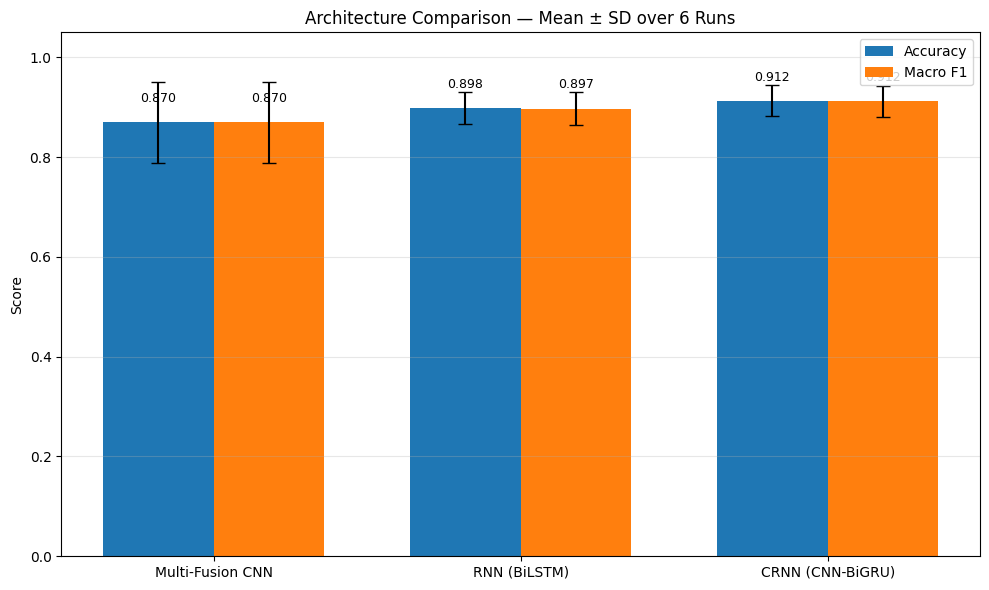

Saved: /content/drive/MyDrive/פרוייקט גמר- זיהוי רעשים/architecture_comparison_6runs/figures/architecture_accuracy_macro_f1_mean_std.png


In [ ]:
# ============================================================
# 18. Accuracy + Macro F1 comparison with error bars
# ============================================================
architectures = list(
    MODEL_BUILDERS.keys()
)

x = np.arange(
    len(architectures)
)

width = 0.36


def summary_value(
    architecture,
    column,
):
    return summary_df.loc[
        summary_df["architecture"]
        == architecture,
        column,
    ].iloc[0]


acc_means = [
    summary_value(
        a,
        "accuracy_mean",
    )
    for a in architectures
]

acc_stds = [
    summary_value(
        a,
        "accuracy_std",
    )
    for a in architectures
]

f1_means = [
    summary_value(
        a,
        "macro_f1_mean",
    )
    for a in architectures
]

f1_stds = [
    summary_value(
        a,
        "macro_f1_std",
    )
    for a in architectures
]

fig, ax = plt.subplots(
    figsize=(10, 6)
)

bars_acc = ax.bar(
    x - width / 2,
    acc_means,
    width,
    yerr=acc_stds,
    capsize=5,
    label="Accuracy",
)

bars_f1 = ax.bar(
    x + width / 2,
    f1_means,
    width,
    yerr=f1_stds,
    capsize=5,
    label="Macro F1",
)

ax.set_ylabel("Score")
ax.set_ylim(0, 1.05)

ax.set_xticks(x)
ax.set_xticklabels(
    architectures
)

ax.set_title(
    "Architecture Comparison "
    "— Mean ± SD over 6 Runs"
)

ax.grid(
    axis="y",
    alpha=0.3,
)

ax.legend()

for bars, means in [
    (bars_acc, acc_means),
    (bars_f1, f1_means),
]:
    for bar, mean_value in zip(
        bars,
        means,
    ):
        ax.text(
            bar.get_x()
            + bar.get_width() / 2,
            min(
                mean_value + 0.035,
                1.02,
            ),
            f"{mean_value:.3f}",
            ha="center",
            va="bottom",
            fontsize=9,
        )

fig.tight_layout()

comparison_path = (
    FIGURE_DIR
    / (
        "architecture_accuracy_"
        "macro_f1_mean_std.png"
    )
)

fig.savefig(
    comparison_path,
    dpi=200,
    bbox_inches="tight",
)

plt.show()

print(
    "Saved:",
    comparison_path,
)

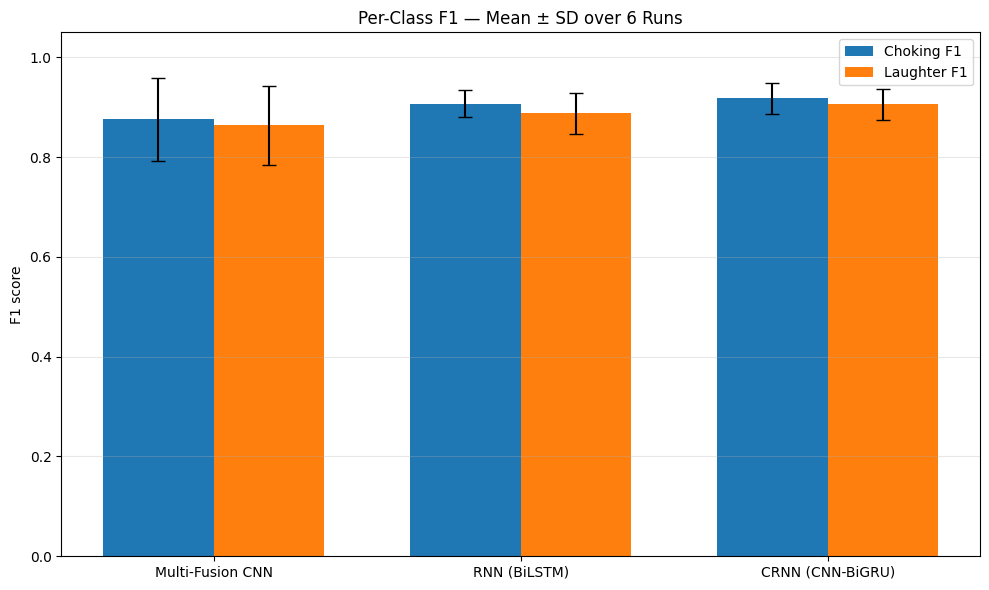

Saved: /content/drive/MyDrive/פרוייקט גמר- זיהוי רעשים/architecture_comparison_6runs/figures/architecture_class_f1_mean_std.png


In [ ]:
# ============================================================
# 19. Per-class F1 comparison
# ============================================================
choking_means = [
    summary_value(
        a,
        "choking_f1_mean",
    )
    for a in architectures
]

choking_stds = [
    summary_value(
        a,
        "choking_f1_std",
    )
    for a in architectures
]

laughter_means = [
    summary_value(
        a,
        "laughter_f1_mean",
    )
    for a in architectures
]

laughter_stds = [
    summary_value(
        a,
        "laughter_f1_std",
    )
    for a in architectures
]

fig, ax = plt.subplots(
    figsize=(10, 6)
)

ax.bar(
    x - width / 2,
    choking_means,
    width,
    yerr=choking_stds,
    capsize=5,
    label="Choking F1",
)

ax.bar(
    x + width / 2,
    laughter_means,
    width,
    yerr=laughter_stds,
    capsize=5,
    label="Laughter F1",
)

ax.set_ylabel("F1 score")
ax.set_ylim(0, 1.05)

ax.set_xticks(x)
ax.set_xticklabels(
    architectures
)

ax.set_title(
    "Per-Class F1 "
    "— Mean ± SD over 6 Runs"
)

ax.grid(
    axis="y",
    alpha=0.3,
)

ax.legend()
fig.tight_layout()

class_f1_path = (
    FIGURE_DIR
    / "architecture_class_f1_mean_std.png"
)

fig.savefig(
    class_f1_path,
    dpi=200,
    bbox_inches="tight",
)

plt.show()

print(
    "Saved:",
    class_f1_path,
)

# 20. Confusion matrices over six runs

For each architecture, every cell is summarized as:

`mean count ± sample standard deviation`

This avoids over-interpreting a single lucky or unlucky confusion matrix.

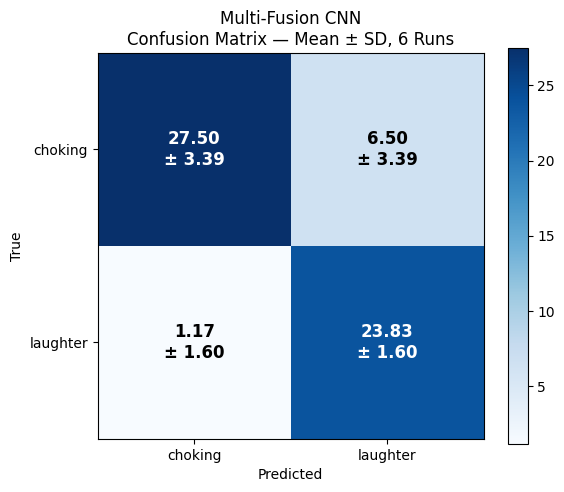


 Multi-Fusion CNN
Mean confusion matrix:
[[27.5    6.5  ]
 [ 1.167 23.833]]
SD confusion matrix:
[[3.391 3.391]
 [1.602 1.602]]


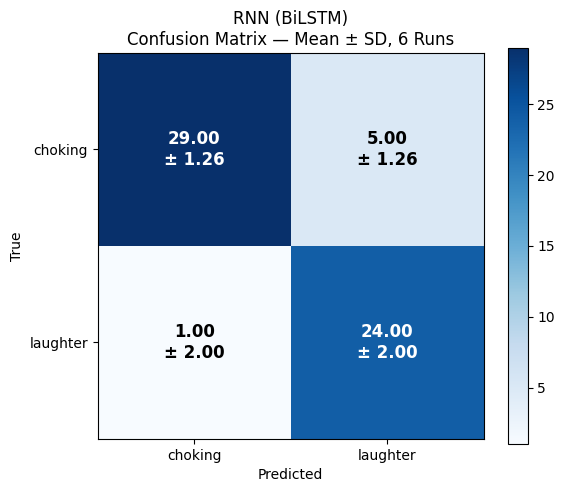


 RNN (BiLSTM)
Mean confusion matrix:
[[29.  5.]
 [ 1. 24.]]
SD confusion matrix:
[[1.265 1.265]
 [2.    2.   ]]


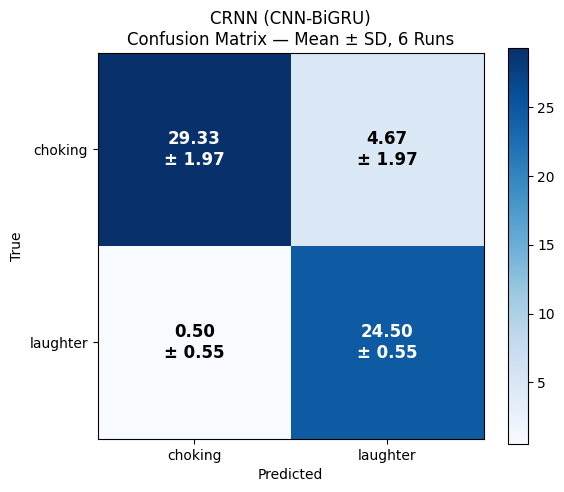


 CRNN (CNN-BiGRU)
Mean confusion matrix:
[[29.333  4.667]
 [ 0.5   24.5  ]]
SD confusion matrix:
[[1.966 1.966]
 [0.548 0.548]]


In [ ]:
# ============================================================
# 20. Mean ± SD confusion matrices
# ============================================================
mean_confusion = {}
std_confusion = {}

for architecture in architectures:
    cms = np.stack(
        confusion_matrices[
            architecture
        ],
        axis=0,
    )

    mean_cm = cms.mean(
        axis=0
    )

    std_cm = cms.std(
        axis=0,
        ddof=1,
    )

    mean_confusion[
        architecture
    ] = mean_cm

    std_confusion[
        architecture
    ] = std_cm

    fig, ax = plt.subplots(
        figsize=(6, 5)
    )

    image = ax.imshow(
        mean_cm,
        cmap="Blues",
    )

    ax.set_title(
        f"{architecture}\n"
        "Confusion Matrix "
        "— Mean ± SD, 6 Runs"
    )

    ax.set_xlabel(
        "Predicted"
    )

    ax.set_ylabel(
        "True"
    )

    ax.set_xticks(
        range(NUM_CLASSES)
    )

    ax.set_yticks(
        range(NUM_CLASSES)
    )

    ax.set_xticklabels(
        CLASS_NAMES
    )

    ax.set_yticklabels(
        CLASS_NAMES
    )

    threshold = (
        mean_cm.max() / 2
    )

    for i in range(
        NUM_CLASSES
    ):
        for j in range(
            NUM_CLASSES
        ):
            text = (
                f"{mean_cm[i, j]:.2f}"
                f"\n± {std_cm[i, j]:.2f}"
            )

            ax.text(
                j,
                i,
                text,
                ha="center",
                va="center",
                color=(
                    "white"
                    if mean_cm[i, j]
                    > threshold
                    else "black"
                ),
                fontsize=12,
                fontweight="bold",
            )

    fig.colorbar(
        image,
        ax=ax,
    )

    fig.tight_layout()

    cm_path = (
        FIGURE_DIR
        / (
            f"{MODEL_SLUGS[architecture]}"
            "_confusion_mean_std.png"
        )
    )

    fig.savefig(
        cm_path,
        dpi=200,
        bbox_inches="tight",
    )

    plt.show()

    print(
        "\n",
        architecture,
    )

    print(
        "Mean confusion matrix:"
    )

    print(
        np.round(
            mean_cm,
            3,
        )
    )

    print(
        "SD confusion matrix:"
    )

    print(
        np.round(
            std_cm,
            3,
        )
    )

# 21. Prediction-agreement check

This directly addresses the earlier case where two architectures produced the same confusion matrix.

For each paired seed and architecture pair, the notebook reports:

- **prediction agreement** — fraction of test files receiving the same prediction;
- **exact same predictions** — whether every test-file decision is identical;
- **same confusion matrix** — whether only the aggregate error counts are identical.

Thus, identical metrics no longer have to be guessed about.

In [ ]:
# ============================================================
# 21. Pairwise prediction agreement
# ============================================================
agreement_rows = []

for run_number, seed in enumerate(
    RUN_SEEDS,
    start=1,
):
    for (
        architecture_a,
        architecture_b,
    ) in combinations(
        architectures,
        2,
    ):
        labels_a = run_labels[
            (architecture_a, run_number)
        ]

        labels_b = run_labels[
            (architecture_b, run_number)
        ]

        paths_a = run_paths[
            (architecture_a, run_number)
        ]

        paths_b = run_paths[
            (architecture_b, run_number)
        ]

        assert np.array_equal(
            labels_a,
            labels_b,
        )

        assert (
            paths_a == paths_b
        ), (
            "Test file ordering differs "
            "between architecture runs."
        )

        preds_a = run_predictions[
            (architecture_a, run_number)
        ]

        preds_b = run_predictions[
            (architecture_b, run_number)
        ]

        cm_a = confusion_matrix(
            labels_a,
            preds_a,
            labels=list(
                range(NUM_CLASSES)
            ),
        )

        cm_b = confusion_matrix(
            labels_b,
            preds_b,
            labels=list(
                range(NUM_CLASSES)
            ),
        )

        agreement_rows.append(
            {
                "run": run_number,
                "seed": seed,
                "architecture_a": (
                    architecture_a
                ),
                "architecture_b": (
                    architecture_b
                ),
                "prediction_agreement": float(
                    np.mean(
                        preds_a == preds_b
                    )
                ),
                "exact_same_predictions": bool(
                    np.array_equal(
                        preds_a,
                        preds_b,
                    )
                ),
                "same_confusion_matrix": bool(
                    np.array_equal(
                        cm_a,
                        cm_b,
                    )
                ),
            }
        )

agreement_df = pd.DataFrame(
    agreement_rows
)

display(
    agreement_df.sort_values(
        [
            "run",
            "architecture_a",
            "architecture_b",
        ]
    ).reset_index(
        drop=True
    )
)

,run,seed,architecture_a,architecture_b,prediction_agreement,exact_same_predictions,same_confusion_matrix
0,1,42,Multi-Fusion CNN,CRNN (CNN-BiGRU),0.813559,False,False
1,1,42,Multi-Fusion CNN,RNN (BiLSTM),0.813559,False,False
2,1,42,RNN (BiLSTM),CRNN (CNN-BiGRU),0.932203,False,True
3,2,43,Multi-Fusion CNN,CRNN (CNN-BiGRU),0.932203,False,False
4,2,43,Multi-Fusion CNN,RNN (BiLSTM),0.932203,False,False
5,2,43,RNN (BiLSTM),CRNN (CNN-BiGRU),0.898305,False,False
6,3,44,Multi-Fusion CNN,CRNN (CNN-BiGRU),0.898305,False,False
7,3,44,Multi-Fusion CNN,RNN (BiLSTM),0.881356,False,False
8,3,44,RNN (BiLSTM),CRNN (CNN-BiGRU),0.915254,False,False
9,4,45,Multi-Fusion CNN,CRNN (CNN-BiGRU),0.864407,False,False


In [ ]:
# ============================================================
# 22. Save all results
# ============================================================
RUN_RESULTS_CSV = (
    OUT_DIR
    / "all_runs_metrics.csv"
)

SUMMARY_CSV = (
    OUT_DIR
    / "architecture_summary_mean_std.csv"
)

PRETTY_SUMMARY_CSV = (
    OUT_DIR
    / "architecture_summary_pretty.csv"
)

PREDICTIONS_CSV = (
    OUT_DIR
    / "all_test_predictions.csv"
)

AGREEMENT_CSV = (
    OUT_DIR
    / "prediction_agreement.csv"
)

RESULTS_JSON = (
    OUT_DIR
    / "architecture_comparison_results.json"
)

results_df.to_csv(
    RUN_RESULTS_CSV,
    index=False,
)

summary_df.to_csv(
    SUMMARY_CSV,
    index=False,
)

pretty_summary_df.to_csv(
    PRETTY_SUMMARY_CSV,
    index=False,
)

predictions_df.to_csv(
    PREDICTIONS_CSV,
    index=False,
)

agreement_df.to_csv(
    AGREEMENT_CSV,
    index=False,
)

json_payload = {
    "experiment": {
        "architectures": architectures,
        "run_seeds": RUN_SEEDS,
        "num_runs_per_architecture": NUM_RUNS,
        "input_shape": list(INPUT_SHAPE),
        "class_names": CLASS_NAMES,
        "batch_size": BATCH_SIZE,
        "learning_rate": LEARNING_RATE,
        "weight_decay": WEIGHT_DECAY,
        "num_epochs": NUM_EPOCHS,
        "early_stopping_patience": EARLY_STOPPING_PATIENCE,
        "scheduler_patience": SCHEDULER_PATIENCE,
        "scheduler_factor": SCHEDULER_FACTOR,
        "grad_clip": GRAD_CLIP,
        "use_class_weights": USE_CLASS_WEIGHTS,
        "class_weights": (
            None
            if class_weights is None
            else [
                float(v)
                for v in (
                    class_weights
                    .detach()
                    .cpu()
                    .numpy()
                )
            ]
        ),
    },

    "parameter_counts": {
        architecture: int(count)
        for architecture, count
        in parameter_counts.items()
    },

    "summary": (
        summary_df
        .to_dict(
            orient="records"
        )
    ),

    "agreement": (
        agreement_df
        .to_dict(
            orient="records"
        )
    ),

    "mean_confusion_matrices": {
        architecture: (
            mean_confusion[
                architecture
            ].tolist()
        )
        for architecture
        in architectures
    },

    "std_confusion_matrices": {
        architecture: (
            std_confusion[
                architecture
            ].tolist()
        )
        for architecture
        in architectures
    },
}

with open(
    RESULTS_JSON,
    "w",
    encoding="utf-8",
) as f:
    json.dump(
        json_payload,
        f,
        indent=2,
        ensure_ascii=False,
    )

print("Saved:")

for path in [
    RUN_RESULTS_CSV,
    SUMMARY_CSV,
    PRETTY_SUMMARY_CSV,
    PREDICTIONS_CSV,
    AGREEMENT_CSV,
    RESULTS_JSON,
]:
    print(" ", path)

Saved:
  /content/drive/MyDrive/פרוייקט גמר- זיהוי רעשים/architecture_comparison_6runs/all_runs_metrics.csv
  /content/drive/MyDrive/פרוייקט גמר- זיהוי רעשים/architecture_comparison_6runs/architecture_summary_mean_std.csv
  /content/drive/MyDrive/פרוייקט גמר- זיהוי רעשים/architecture_comparison_6runs/architecture_summary_pretty.csv
  /content/drive/MyDrive/פרוייקט גמר- זיהוי רעשים/architecture_comparison_6runs/all_test_predictions.csv
  /content/drive/MyDrive/פרוייקט גמר- זיהוי רעשים/architecture_comparison_6runs/prediction_agreement.csv
  /content/drive/MyDrive/פרוייקט גמר- זיהוי רעשים/architecture_comparison_6runs/architecture_comparison_results.json


In [ ]:
# ============================================================
# 23. Final report-ready result
# ============================================================
print(
    "FINAL ARCHITECTURE COMPARISON"
)

print(
    "Each value is mean ± sample SD "
    "over six runs.\n"
)

display(
    pretty_summary_df
)

best_acc_idx = (
    summary_df[
        "accuracy_mean"
    ].idxmax()
)

best_f1_idx = (
    summary_df[
        "macro_f1_mean"
    ].idxmax()
)

print(
    "Highest mean test accuracy:",
    summary_df.loc[
        best_acc_idx,
        "architecture",
    ],
    pm(
        summary_df.loc[
            best_acc_idx,
            "accuracy_mean",
        ],
        summary_df.loc[
            best_acc_idx,
            "accuracy_std",
        ],
    ),
)

print(
    "Highest mean macro F1:",
    summary_df.loc[
        best_f1_idx,
        "architecture",
    ],
    pm(
        summary_df.loc[
            best_f1_idx,
            "macro_f1_mean",
        ],
        summary_df.loc[
            best_f1_idx,
            "macro_f1_std",
        ],
    ),
)

print(
    "\nOutput directory:"
)

print(
    OUT_DIR
)

FINAL ARCHITECTURE COMPARISON
Each value is mean ± sample SD over six runs.



,Architecture,Parameters,Accuracy,Choking Precision,Choking Recall,Choking F1,Laughter Precision,Laughter Recall,Laughter F1,Macro F1
0,Multi-Fusion CNN,"25,058",0.8701 ± 0.0814,0.9568 ± 0.0631,0.8088 ± 0.0997,0.8756 ± 0.0837,0.7908 ± 0.0910,0.9533 ± 0.0641,0.8636 ± 0.0788,0.8696 ± 0.0812
1,RNN (BiLSTM),"241,874",0.8983 ± 0.0322,0.9706 ± 0.0572,0.8529 ± 0.0372,0.9066 ± 0.0270,0.8289 ± 0.0335,0.9600 ± 0.0800,0.8879 ± 0.0407,0.8972 ± 0.0334
2,CRNN (CNN-BiGRU),"181,474",0.9124 ± 0.0311,0.9838 ± 0.0178,0.8627 ± 0.0578,0.9183 ± 0.0311,0.8435 ± 0.0567,0.9800 ± 0.0219,0.9055 ± 0.0308,0.9119 ± 0.0309


Highest mean test accuracy: CRNN (CNN-BiGRU) 0.9124 ± 0.0311
Highest mean macro F1: CRNN (CNN-BiGRU) 0.9119 ± 0.0309

Output directory:
/content/drive/MyDrive/פרוייקט גמר- זיהוי רעשים/architecture_comparison_6runs


## How to interpret the final comparison

Use the **mean ± SD** table rather than choosing one favorable run.

A useful order is:

1. Compare mean test accuracy and macro F1.
2. Compare the size of the architecture difference with the run-to-run standard deviations.
3. Compare choking and laughter precision/recall/F1 separately.
4. Use the mean confusion matrices to identify which class is being confused.
5. If two models have identical aggregate results, use the prediction-agreement table to see whether they actually classified the same recordings identically.

If two architectures differ only slightly and the difference is comparable to their run-to-run variability, the defensible conclusion is that this experiment does **not show a clear practical advantage** for one of them on the current dataset.